# Time-shifted Brownian motion

$$ dX_t = 0.5\,dt + dB_t^P $$

Estimate $\sigma$ from quadratic variation, recover $B^Q$, estimate $\psi_{21}$,
recover $\mu$ and $B^P$, then fit SSISDE. `S` denotes the sampled path $X$.
Run all cells with the project Python environment. Figures are saved in this folder.

Compare three final SSISDE fits, using noise from Method 1, Method 2 and ODE2. Each fit uses the same degree-5 libraries, seven-fold cross-validation and seven elastic-net mixing values. The final table reports noise, drift and diffusion errors.


In [1]:
from pathlib import Path
import os
import sys

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]
PROJECT_ROOT = next((p for p in roots if (p / 'models/stochastic_sindy.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the SSISDE checkout first. On Colab, download it with the Black-Scholes setup cell.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/constant')
RESULTS = PROJECT_ROOT / 'outputs/constant'
RESULTS.mkdir(parents=True, exist_ok=True)


In [2]:
%pip install -q -r ../../requirements.txt



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pysindy as ps
from sklearn import linear_model
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
from tqdm import tqdm
import iisignature

from models.diffusion_tuning import diffusion_model, fit_diffusion


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


## Simulate $X$

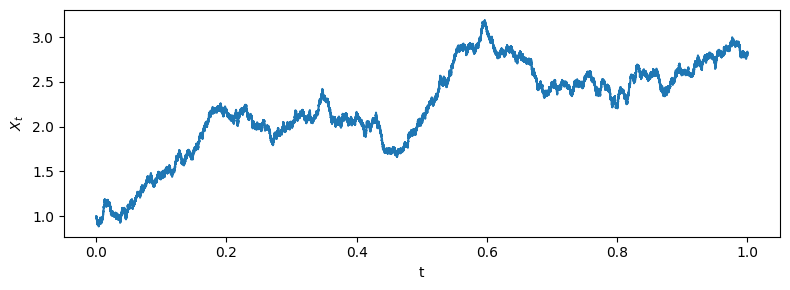

In [4]:
from data_generation.constant import generate_data
N, T, S0, seed = 100000, 1.0, 1.0, 31
r, sigm = 0.5, 1.0
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed, r=r, sigm=sigm)

plt.figure(figsize=(8, 3))
plt.plot(t, S_)
plt.xlabel('t')
plt.ylabel(r'$X_t$')
plt.tight_layout()
plt.savefig('path.png', dpi=200)
plt.show()


## Estimate $\sigma$ from quadratic variation

Fit a degree-4 polynomial for $\sigma^2$. Select `threshold` and `nu` using the
last 20% of the path, leaving a three-sample gap after the training data.
The known $\sigma$ is used only to report error. The selected fit is then
refitted on the full path. Fits that do not converge, or give zero or negative variance, are rejected.
The search uses `max_iter=10000` and `tol=1e-8`; the original fit retains its
supplied settings for comparison.


In [5]:
from models.quadratic_variation import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)


  0%|          | 0/100000 [00:00<?, ?it/s]

 13%|█▎        | 13419/100000 [00:00<00:00, 134179.25it/s]

 27%|██▋       | 26837/100000 [00:00<00:00, 86201.58it/s] 

 36%|███▋      | 36418/100000 [00:00<00:00, 67002.60it/s]

 44%|████▍     | 43856/100000 [00:00<00:00, 56318.85it/s]

...

 94%|█████████▎| 93655/100000 [00:02<00:00, 20761.11it/s]

 96%|█████████▌| 95722/100000 [00:02<00:00, 20471.72it/s]

 98%|█████████▊| 97761/100000 [00:02<00:00, 20199.80it/s]

100%|█████████▉| 99774/100000 [00:02<00:00, 19874.44it/s]

100%|██████████| 100000/100000 [00:02<00:00, 33889.88it/s]

In [6]:
thresholds = [1.0, 3.1, 5.0]
nus = [0.1, 0.2, 0.5]

baseline = diffusion_model(3.1, 0.2)
baseline.fit(S_.reshape(-1, 1), t, x_dot=dQV.reshape(-1, 1))
baseline_sigma = np.sqrt(baseline.predict(S_.reshape(-1, 1))).ravel()

model, sigma_settings, sigma_search = fit_diffusion(
    S_, t, dQV, thresholds, nus, max_iter=10000, tol=1e-8,
)
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_equation = model.equations(precision=6)[0]
print(f"threshold = {sigma_settings['threshold']}, nu = {sigma_settings['nu']}")
print('sigma^2(X) =', sigma_equation)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))


threshold = 5.0, nu = 0.5
sigma^2(X) = 1.000393 1


1496

Original settings: sigma RMSE = 0.000196435
Selected settings: sigma RMSE = 0.000196435


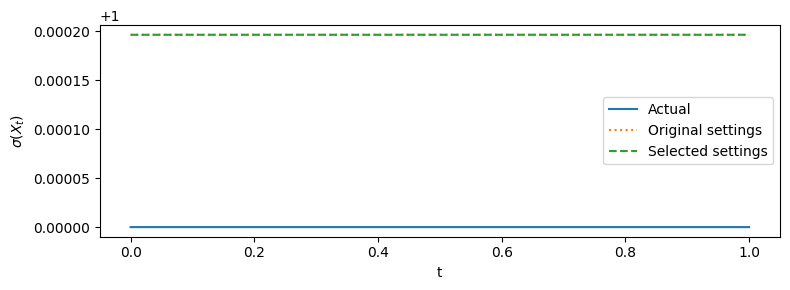

In [7]:
sigma_rmse = float(np.sqrt(np.mean((sigma_pred_.ravel() - sigma_exact_)**2)))
baseline_sigma_rmse = float(np.sqrt(np.mean((baseline_sigma - sigma_exact_)**2)))
print(f'Original settings: sigma RMSE = {baseline_sigma_rmse:.6g}')
print(f'Selected settings: sigma RMSE = {sigma_rmse:.6g}')

plt.figure(figsize=(8, 3))
plt.plot(t, sigma_exact_, label='Actual')
plt.plot(t, baseline_sigma, ':', label='Original settings')
plt.plot(t, sigma_pred_, '--', label='Selected settings')
plt.xlabel('t')
plt.ylabel(r'$\sigma(X_t)$')
plt.legend()
plt.tight_layout()
plt.savefig('diffusion.png', dpi=200)
plt.show()


## Recover $B^Q$ and estimate $\psi_{21}$

In [8]:
from models.q_brownian_motion import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)

keep_cols = [0, 1, 3, 4, 5, 13]
from models.signature_regression import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)
from models.coarse_diffusion_derivatives import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


  0%|          | 0/1000 [00:00<?, ?it/s]

 18%|█▊        | 185/1000 [00:00<00:00, 1397.28it/s]

 35%|███▌      | 352/1000 [00:00<00:00, 1535.22it/s]

 55%|█████▍    | 547/1000 [00:00<00:00, 1707.89it/s]

 74%|███████▍  | 740/1000 [00:00<00:00, 1791.43it/s]

 94%|█████████▎| 935/1000 [00:00<00:00, 1844.70it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1760.96it/s]

## Recover $\mu$

Method 1 estimates $\psi_{21}$ by signature regression. Method 2 uses the
diffusion estimate. ODE2 uses the additional initial slope $\mu'(X_0)=0$.
All three start from the supplied initial drift $\mu(X_0)$.


In [9]:
from models.drift_coefficients import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)
from models.drift_recovery import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)

lambda_0 = 0.0
from models.drift_recovery_from_ODE2 import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


Method 1: drift RMSE = 0.000348755
Method 2: drift RMSE = 0
ODE2: drift RMSE = 2.96946e-10


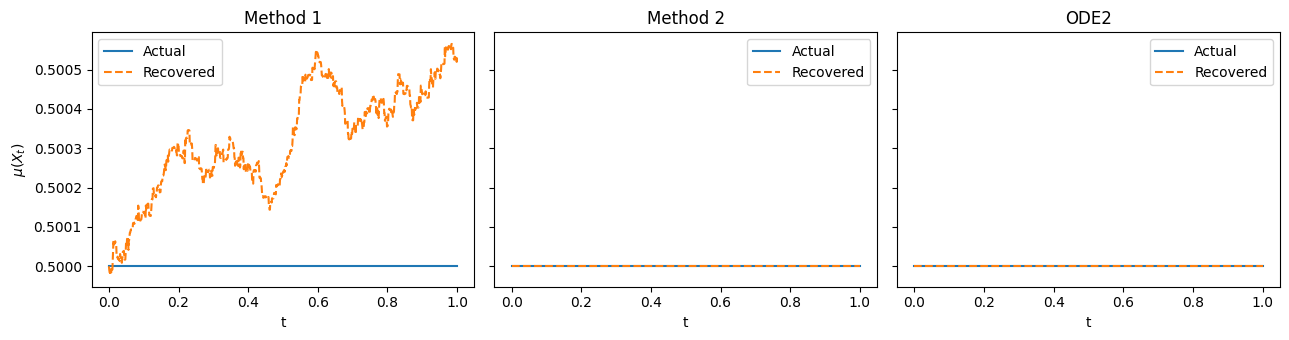

In [10]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.6g}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


## Recover $B^P$ using Method 1

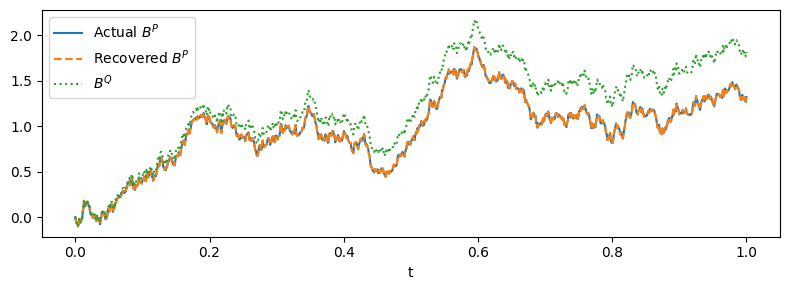

In [11]:
from models.p_brownian_motion import recover_p_noise
model = "Psi_approx_BS"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
model = 'constant'

plt.figure(figsize=(8, 3))
plt.plot(t, W, label=r'Actual $B^P$')
plt.plot(t, BP, '--', label=r'Recovered $B^P$')
plt.plot(t, BQ, ':', label=r'$B^Q$')
plt.xlabel('t')
plt.legend()
plt.tight_layout()
plt.savefig('noise.png', dpi=200)
plt.show()


## SSISDE

### Drift from Method 1

MSE: 6.942e-16
μ(X) = 0.499733 + 0.000265495*X
σ(X) = 1.0002 + -7.42992e-08*X
[CV best] alpha=0.000172, l1_ratio (rho)=0.30


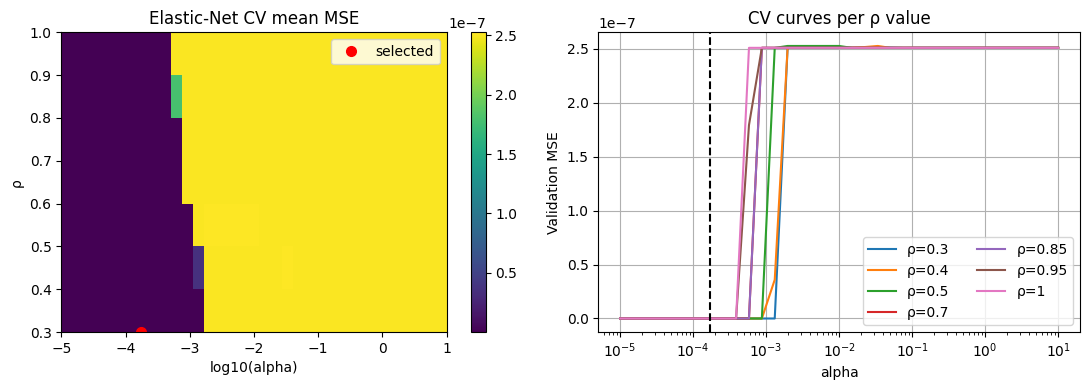

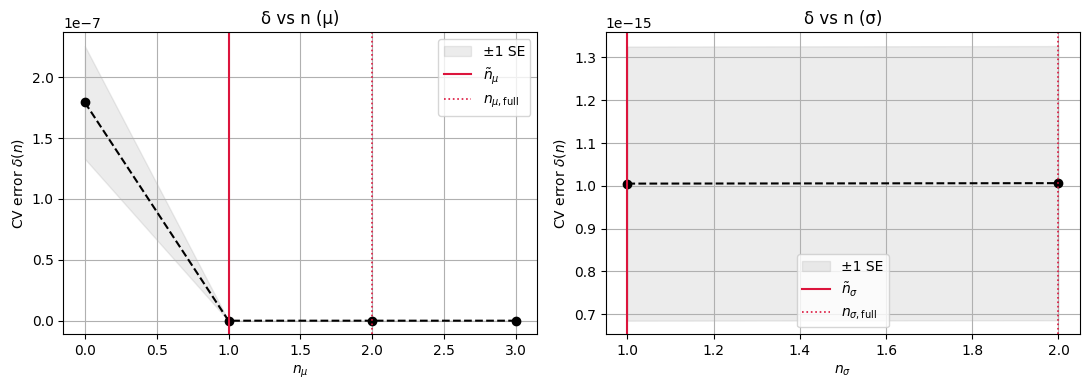

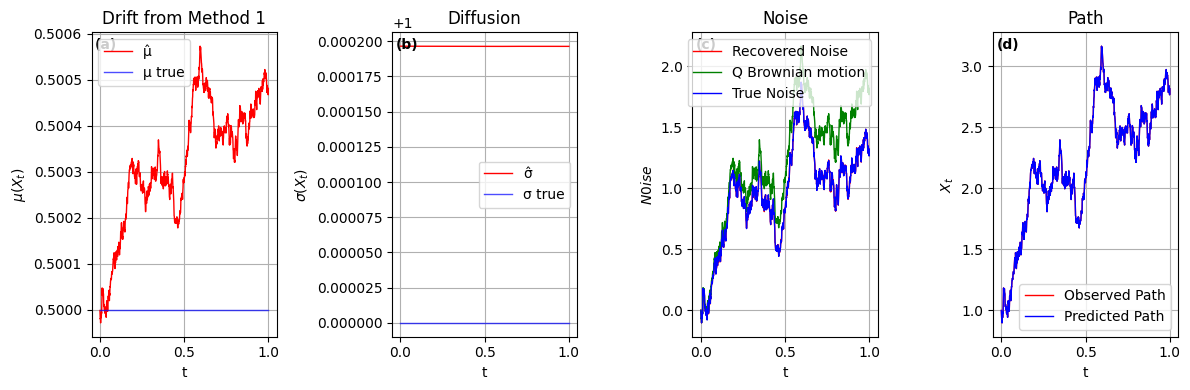

### Drift from Method 2

MSE: 3.232e-31
μ(X) = 0.5
σ(X) = 1.0002
[CV best] alpha=0.00131, l1_ratio (rho)=0.30


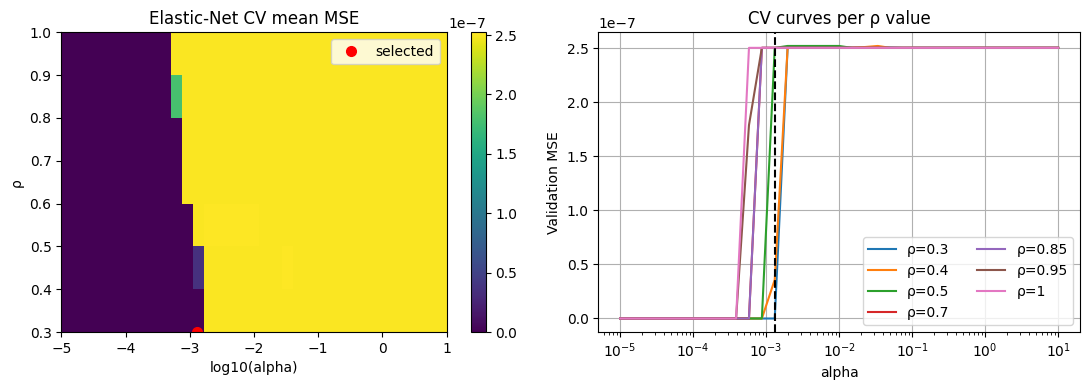

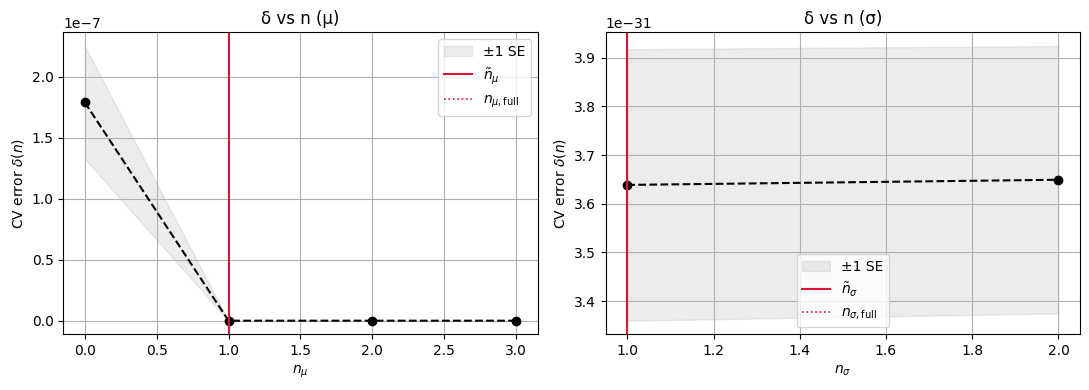

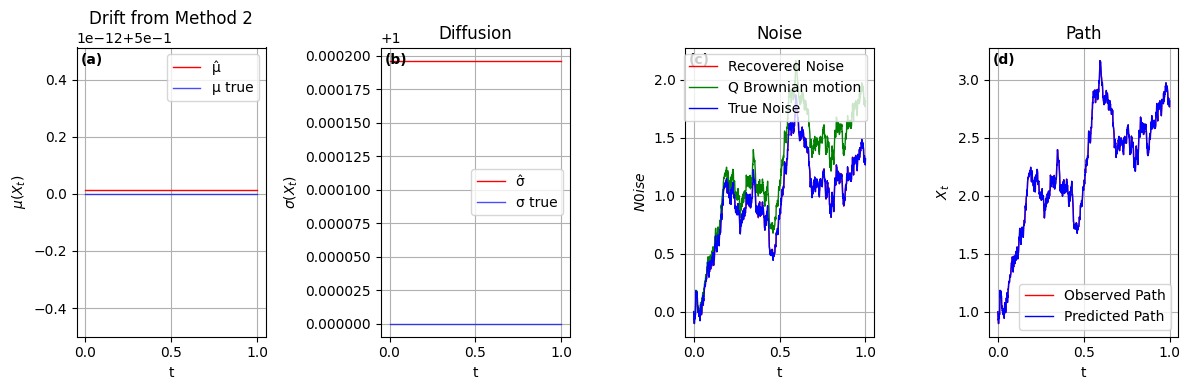

### Drift from ODE2

MSE: 8.452e-26
μ(X) = 0.5
σ(X) = 1.0002
[CV best] alpha=0.00131, l1_ratio (rho)=0.30


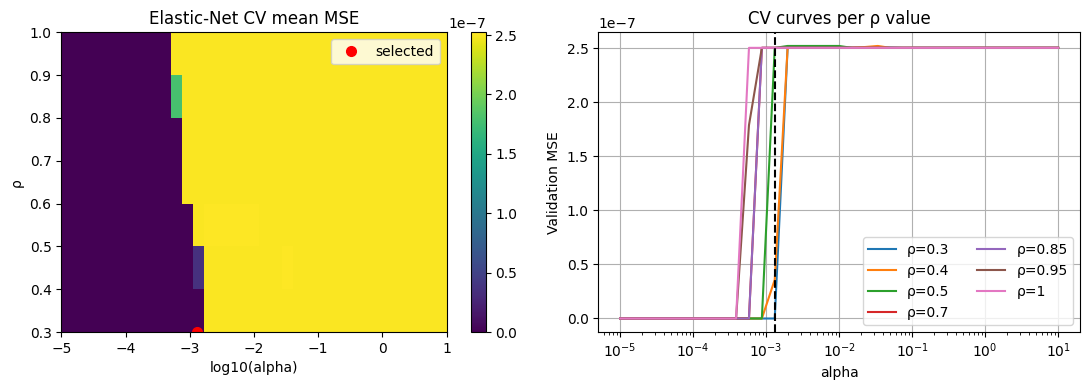

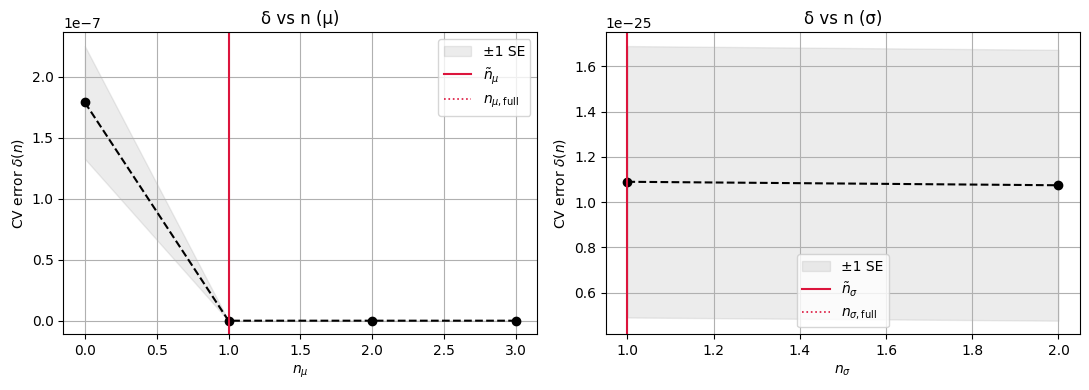

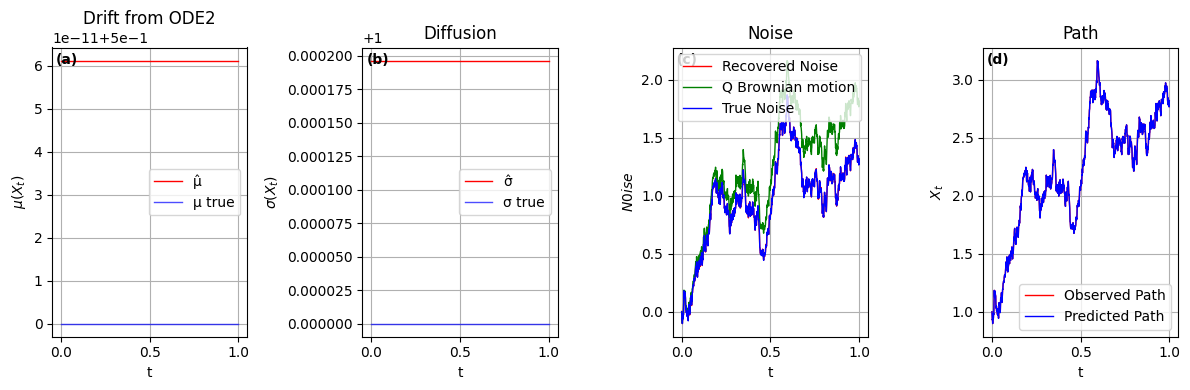

| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |
|---|---:|---:|---:|
| Method 1 | 0.00320509 | 0.000347639 | 0.000196416 |
| Method 2 | 0.00319073 | 1.32117e-14 | 0.000196435 |
| ODE2 | 0.00319073 | 6.11839e-11 | 0.000196435 |

In [12]:
from models.stochastic_sindy import StochSINDy
from models.p_brownian_motion import recover_p_noise
from threadpoolctl import threadpool_limits
from IPython.display import Markdown, display
import json

recovered_drifts = {"Method 1": mu_pred1, "Method 2": mu_pred2, "ODE2": mu_pred11}
identifiers, noise_paths, ssisde_comparison, comparison_paths = {}, {}, {}, {}

for method_name, recovered_drift in recovered_drifts.items():
    method_key = method_name.lower().replace(" ", "_")
    BP_method, dt_method, _ = recover_p_noise(BQ, recovered_drift, sigma_pred, T)
    noise_paths[method_name] = BP_method
    identifier_method = StochSINDy(
        mu_deg=5, si_deg=5,
        pen="elasticnet",
        use_cv=True, k=7,
        alphas=np.geomspace(1e-5, 1e1, 35),
        rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
        use_1se=True,
    )
    with threadpool_limits(limits=1):
        identifier_method.fit(S, BP_method, dt_method)
    identifiers[method_name] = identifier_method
    output_prefix = f"{model}_{method_key}"
    display(Markdown(f"### Drift from {method_name}"))
    identifier_method.show()
    identifier_method.plot_cv(output_prefix=output_prefix)
    identifier_method.plot_size(count_bias=True, output_prefix=output_prefix)
    identifier_method.plot_results(
        S, BP_method, BQ, W, mu_true=mu_exact, si_true=sigma_exact,
        output_prefix=output_prefix, drift_title=f"Drift from {method_name}",
    )
    mu_fit = identifier_method.mu(S)
    sigma_fit = identifier_method.si(S)
    ssisde_comparison[method_name] = {
        "input_drift_rmse": float(np.sqrt(np.mean((recovered_drift - mu_exact)**2))),
        "noise_rmse": float(np.sqrt(np.mean((BP_method - W)**2))),
        "drift_rmse": float(np.sqrt(np.mean((mu_fit - mu_exact)**2))),
        "diffusion_rmse": float(np.sqrt(np.mean((sigma_fit - sigma_exact)**2))),
        "increment_mse": identifier_method.mse,
        "mu": identifier_method._fmt_poly(identifier_method.mu_c),
        "sigma": identifier_method._fmt_poly(identifier_method.si_c),
        "alpha": identifier_method.best_a,
        "rho": identifier_method.best_r,
    }
    comparison_paths[f"BP_{method_key}"] = BP_method
    comparison_paths[f"input_drift_{method_key}"] = recovered_drift
    comparison_paths[f"mu_fit_{method_key}"] = mu_fit
    comparison_paths[f"sigma_fit_{method_key}"] = sigma_fit

(RESULTS / "ssisde_comparison.json").write_text(json.dumps(ssisde_comparison, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / "ssisde_comparison_paths.npz", S=S, BQ=BQ, W=W,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    dt=dt, **comparison_paths)
rows = ["| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |",
        "|---|---:|---:|---:|"]
for method_name, values in ssisde_comparison.items():
    rows.append(f"| {method_name} | {values['noise_rmse']:.6g} | "
                f"{values['drift_rmse']:.6g} | {values['diffusion_rmse']:.6g} |")
display(Markdown("\n".join(rows)))
identifier = identifiers["Method 1"]


In [13]:
results = {
    'ssisde_comparison': ssisde_comparison,
    'experiment': 'constant',
    'seed': seed,
    'samples': N,
    'state_range': [float(S_.min()), float(S_.max())],
    'sigma_settings': sigma_settings,
    'sigma_squared_equation': sigma_equation,
    'baseline_sigma_rmse': baseline_sigma_rmse,
    'sigma_rmse': sigma_rmse,
    'drift_rmse': drift_rmse,
    'noise_rmse': float(np.sqrt(np.mean((BP - W)**2))),
    'ssisde_increment_mse': identifier.mse,
    'ssisde_drift_rmse': float(np.sqrt(np.mean((identifier.mu(S) - mu_exact)**2))),
    'ssisde_diffusion_rmse': float(np.sqrt(np.mean((identifier.si(S) - sigma_exact)**2))),
    'ssisde_mu': identifier._fmt_poly(identifier.mu_c),
    'ssisde_sigma': identifier._fmt_poly(identifier.si_c),
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2))
print(f"SSISDE increment MSE: {identifier.mse:.6g}")


SSISDE increment MSE: 6.94185e-16


## Result

The selected diffusion is $\hat\sigma \approx 1.000196$. Method 2 and ODE2 recover the constant drift to numerical accuracy; Method 1 has a small regression error. The selected and original diffusion estimates coincide.
